In [1]:
import pandas as pd
import seaborn as sns


In [2]:
insurence_data= pd.read_csv("insurance.csv")

In [3]:
X= insurence_data.drop(columns=["charges","region"])
y= insurence_data["charges"]

#mapping data to reduce alphabatical characters

X["sex"]= X["sex"].map({"female": 1,"male":0})
X["smoker"]= X["smoker"].map({"yes": 1,"no":0})

In [4]:
X.head()

,age,sex,bmi,children,smoker
0,19,1,27.900,0,1
1,18,0,33.770,1,0
2,28,0,33.000,3,0
3,33,0,22.705,0,0
4,32,0,28.880,0,0


In [5]:
#train and test split
from sklearn.model_selection import train_test_split # tts will split data into 4 parts

X_train, X_test, y_train, y_test= train_test_split(X,y, test_size=0.2, random_state=42) #here randome state will 
#record this same shuffled data before splittng and will give same data when needed (x is the i/p and y is the o/p in both test and train)

In [6]:
#train model 
from sklearn.linear_model import LinearRegression

model= LinearRegression() #this means we have prepared a model
model.fit(X_train,y_train) #fit is used to train the model automatically by sklearn

LinearRegression()

In [7]:
# pridict value
y_pred= model.predict(X_test)

In [8]:
y_pred #know this is the result

array([ 8554.81711589,  6973.58746745, 36798.60416104,  9417.88282303,
       26871.68031081, 11097.38383938,   145.27608963, 16746.1683771 ,
         747.53414191, 11153.67590722, 28518.15016561,  9292.18345421,
        5460.51975119, 38510.48013003, 40359.30938604, 37223.40538064,
       15316.56711945, 36047.50032223,  9326.29049907, 31400.1559532 ,
        4269.64414373, 10464.66374097,  2719.9260555 ,  6579.53742551,
       11232.00255515, 12472.06793446, 14807.11281089,  6066.19283362,
        9535.69029723,  2377.6983797 ,  9475.05690885, 12963.23366722,
        4706.09057393,  3414.674504  ,  4815.64981654, 12484.17176954,
        2359.13614479,  9161.02061228, 33238.67621442, 32743.41702445,
        4274.58967205,  4229.5442107 , 14435.36485176, 11384.66898976,
        8925.70468583, 12480.09178788,  5154.45787816,  3554.10047649,
       35649.60942684,  9276.25523701, 15971.35991397,  2552.75200479,
       12162.99980138,  1062.65132285, 13551.43771934, 12103.65505529,
      

In [9]:
# Evaluate 

from sklearn.metrics import r2_score

r2 =r2_score(y_test, y_pred) # r2_score(the value to be tested on , the value to which it should be compared)
print("r-squared:", r2)

n= X_test.shape[0] #no. of rows
p= X_test.shape[1] # no. of collumns (features)

adj_r2= 1- ((1-r2)*(n-1)/(n-p-1))
print("adjusted_r^2", adj_r2)

r-squared: 0.7811302113434095
adjusted_r^2 0.7769533069797342


In [10]:
# one hot encoding on basis of region

X= insurence_data.drop(columns=["charges"])
y= insurence_data["charges"]

X= pd.get_dummies(X, columns=["region"], drop_first=True ,dtype=int) #this will give a dummie data for all 4 regions and in int format (Dummy Variablr Trap)

X["sex"]= X["sex"].map({"female": 1,"male":0})
X["smoker"]= X["smoker"].map({"yes": 1,"no":0})


In [11]:
X.head()

,age,sex,bmi,children,smoker,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,0,0,1
1,18,0,33.770,1,0,0,1,0
2,28,0,33.000,3,0,0,1,0
3,33,0,22.705,0,0,1,0,0
4,32,0,28.880,0,0,1,0,0


In [12]:
# Again training a model to see the results
X_train, X_test, y_train, y_test= train_test_split(X,y, test_size=0.2, random_state=42)

model= LinearRegression() 
model.fit(X_train,y_train)
y_pred=model.predict(X_test)

In [13]:
r2 =r2_score(y_test, y_pred) 
print("r-squared:", r2)

r-squared: 0.7835929767120724


In [14]:
# Interaction Feature

X= insurence_data.drop(columns=["charges"])
y= insurence_data["charges"]

X= pd.get_dummies(X, columns=["region"], drop_first=True ,dtype=int) 

X["sex"]= X["sex"].map({"female": 1,"male":0})
X["smoker"]= X["smoker"].map({"yes": 1,"no":0})

X["age_smoker"]= X["age"]* X["smoker"]
X["bmi_smoker"]= X["bmi"]* X["smoker"] 

X.head()

,age,sex,bmi,children,smoker,region_northwest,region_southeast,region_southwest,age_smoker,bmi_smoker
0,19,1,27.900,0,1,0,0,1,19,27.9
1,18,0,33.770,1,0,0,1,0,0,0.0
2,28,0,33.000,3,0,0,1,0,0,0.0
3,33,0,22.705,0,0,1,0,0,0,0.0
4,32,0,28.880,0,0,1,0,0,0,0.0


In [15]:
X_train, X_test, y_train, y_test= train_test_split(X,y, test_size=0.2, random_state=42)

model= LinearRegression() 
model.fit(X_train,y_train)
y_pred=model.predict(X_test)

r2 =r2_score(y_test, y_pred) 
print("r-squared:", r2)

# now thats a big difference 

r-squared: 0.865231697953168


In [16]:
#overfitting and underfitting
# r2 training in low & r2 testing is also low - underfit
# r2 training >> r2 testing (is low) - overfit

y_train_pred= model.predict(X_train)
r2_train = r2_score(y_train,y_train_pred)

print("training data r2", r2_train)
print("testing data r2", r2)

# this tells its not over or udederfitting but dataset may be noisy or samll

training data r2 0.8340713711218875
testing data r2 0.865231697953168


In [17]:
# Lasso Regression ,just make the value of alpha non-zero
from sklearn.linear_model import Lasso #this directly imports the lasso model
from sklearn.metrics import mean_squared_error


MSE: 20921006.72913666
MSE: 20890881.000633497
MSE: 20872844.794796687
MSE: 20877828.53237883
MSE: 20868495.29410471
MSE: 20900842.58566421
MSE: 20937537.133939777
MSE: 21115606.53366923
MSE: 20987912.106543407
MSE: 21046489.29389078


<Axes: >

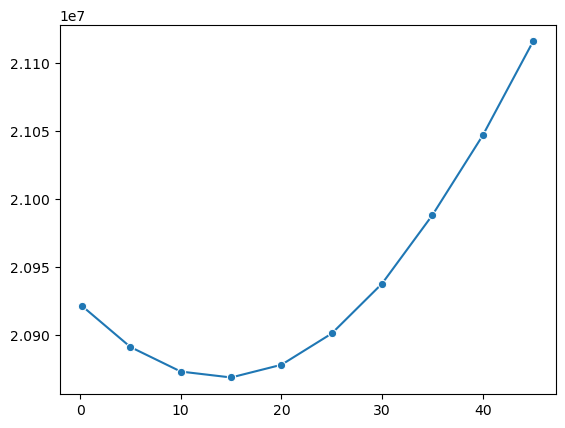

In [18]:
# cheking the correct alpha value comes with trial and error ,so first we loop  
alhas= [0.2,5,10,20,15,25,30,45,35,40]
msqe=[]

for a in alhas:
    lasso_model =Lasso(alpha=a)
    lasso_model.fit(X_train,y_train)
    
    y_pred=lasso_model.predict(X_test)
    
    mse= mean_squared_error(y_test,y_pred)
    msqe.append(mse)
    print("MSE:",mse)

sns.lineplot(x=alhas, y=msqe, marker="o")

#this graph shows ous which alpha value gets ous least error but we use a more simplar approach then a loop we use cros validation

In [22]:
from sklearn.linear_model import LassoCV
a=[00.01, 0.1, 0.5, 1, 2, 3, 4, 5, 10, 15, 20, 30]

lasso_cv_model= LassoCV(
    alphas=a,
    cv=5,
    max_iter=1000, #no. of times model will check the new combinations
    random_state=42
)

lasso_cv_model.fit(X_train, y_train)
y_pred= lasso_cv_model.predict(X_test)
mse= mean_squared_error(y_test, y_pred)
r2= r2_score(y_test, y_pred)
print(f"MSE:{mse}\nr2:{r2}")

MSE:20922527.32662988
r2:0.8652322171937453
[0.01, 0.1, 0.5, 1, 2, 3, 4, 5, 10, 15, 20, 30]
